<a href="https://colab.research.google.com/github/yoloaryan/ML/blob/main/nlp_class_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
np.random.seed(42)
n_samples = 250

data = {
    'Area_SqFt': np.random.randint(500, 3500, size=n_samples),
    'Age_Years': np.random.randint(0, 50, size=n_samples),
    'Distance_KM': np.random.uniform(1, 20, size=n_samples)
}

In [4]:
print(data)

{'Area_SqFt': array([1360, 1794, 1630, 1595, 2138, 2669,  966, 1738,  830, 1982, 2635,
       3419,  630, 2185, 1269, 2891, 2015, 3353, 2933, 1715, 1455, 2824,
       1684,  959,  521, 2800, 1247, 3404,  974, 1582, 3058, 2547, 3247,
       1475, 2306,  689, 3234, 1062, 2399, 1767, 3379, 2028, 1146, 2568,
       3388, 2714, 1797, 2935, 1100, 2863, 2561,  741, 2541, 3324, 3112,
       3445, 1863, 2639, 1890, 1978, 3056, 1275,  534, 2753, 2455, 2085,
       1521, 3113, 1629, 2000, 1202, 2949, 3277, 2079,  661,  701, 2481,
       1495, 2817, 1315,  955, 1775, 1516, 2843, 3267,  837, 1378, 1576,
       1291, 2764, 1263, 2735,  879,  992, 1680, 2562,  564, 3068, 1867,
       1652, 2527, 3195, 1995, 1662, 2022, 3140,  891, 2198,  918, 2836,
        878, 2296, 2778, 2588, 2682,  700, 2363, 1279, 3477, 1002, 2954,
       2251, 1304, 2646, 3231, 2395, 3273, 2070, 1460, 3160, 1985, 3190,
       1528, 1002, 3314,  897, 1370, 3342,  892,  706, 1538, 2381, 3439,
       1984, 1363, 3290, 1063, 1520, 

In [7]:
df=pd.DataFrame(data)
df.head()

,Area_SqFt,Age_Years,Distance_KM
0,1360,40,1.913120
1,1794,32,19.033769
2,1630,39,17.846927
3,1595,38,5.956979
4,2138,17,1.290786


In [8]:
# Generate target: Price = base + (weight * Area) - (weight * Age) - (weight * Distance) + noise
df['Price_USD'] = 50000 + (150 * df['Area_SqFt']) - (2000 * df['Age_Years']) - (5000 * df['Distance_KM']) + np.random.normal(0, 15000, size=n_samples)


In [9]:
print("First 5 rows of the generated dataset:")
display(df.head())

First 5 rows of the generated dataset:


,Area_SqFt,Age_Years,Distance_KM,Price_USD
0,1360,40,1.913120,165089.942223
1,1794,32,19.033769,176036.385680
2,1630,39,17.846927,128406.083805
3,1595,38,5.956979,188759.505416
4,2138,17,1.290786,339487.668483


In [10]:
df.describe()

,Area_SqFt,Age_Years,Distance_KM,Price_USD
count,250.000000,250.000000,250.000000,250.000000
mean,2052.188000,26.260000,10.788626,251958.225589
std,829.127504,14.033823,5.337363,131979.635093
min,501.000000,0.000000,1.259767,-21161.243307
25%,1360.750000,16.000000,6.162462,147915.570953
50%,2028.500000,27.000000,11.152401,243700.185103
75%,2761.250000,37.750000,15.124642,358769.708699
max,3499.000000,49.000000,19.922694,535344.379817


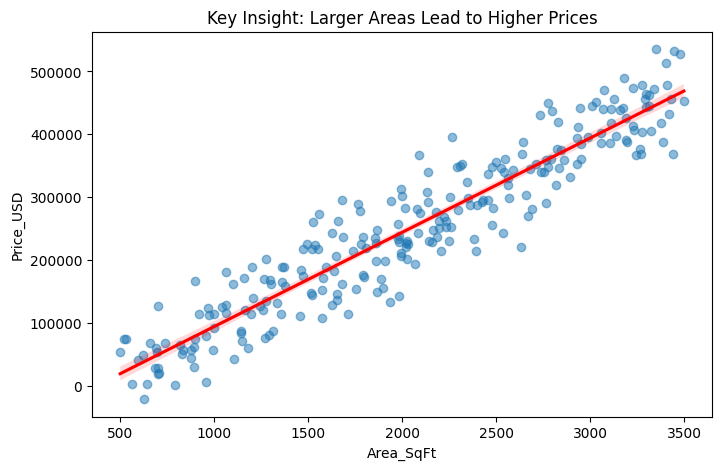

In [11]:
import seaborn as sns
# Visualization: Area vs Price
plt.figure(figsize=(8, 5))
sns.regplot(x='Area_SqFt', y='Price_USD', data=df, scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.title('Key Insight: Larger Areas Lead to Higher Prices')
plt.show()

In [12]:
# 2. Extract Features and Target
X_raw = df[['Area_SqFt', 'Age_Years', 'Distance_KM']].values
y = df['Price_USD'].values
X_raw

array([[1.36000000e+03, 4.00000000e+01, 1.91311956e+00],
       [1.79400000e+03, 3.20000000e+01, 1.90337689e+01],
       [1.63000000e+03, 3.90000000e+01, 1.78469274e+01],
       [1.59500000e+03, 3.80000000e+01, 5.95697884e+00],
       [2.13800000e+03, 1.70000000e+01, 1.29078627e+00],
       [2.66900000e+03, 3.90000000e+01, 1.87352899e+01],
       [9.66000000e+02, 0.00000000e+00, 1.05197578e+01],
       [1.73800000e+03, 1.00000000e+01, 1.12481715e+01],
       [8.30000000e+02, 2.70000000e+01, 1.39953116e+01],
       [1.98200000e+03, 2.40000000e+01, 1.27011721e+01],
       [2.63500000e+03, 4.90000000e+01, 1.89339405e+01],
       [3.41900000e+03, 2.20000000e+01, 1.89407803e+01],
       [6.30000000e+02, 3.00000000e+01, 1.74767797e+01],
       [2.18500000e+03, 2.90000000e+01, 1.30916684e+01],
       [1.26900000e+03, 4.10000000e+01, 1.62180366e+01],
       [2.89100000e+03, 3.40000000e+01, 1.38661985e+01],
       [2.01500000e+03, 6.00000000e+00, 1.18939738e+01],
       [3.35300000e+03, 1.50000

In [13]:
# 3. Perform Feature Scaling (Standardization)
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)


In [14]:
print(f"Scaled Feature Matrix shape: {X.shape}")
print("Mean of scaled features:", X.mean(axis=0).round(2))
print("Std Dev of scaled features:", X.std(axis=0))

Scaled Feature Matrix shape: (250, 3)
Mean of scaled features: [-0. -0. -0.]
Std Dev of scaled features: [1. 1. 1.]


In [15]:
# 2. Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [16]:
# 3. Model Training
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [17]:
# 4. Prediction
y_pred = model.predict(X_test)
y_pred

array([146508.8569946 , 174040.23101954, 162050.92304336,  11150.89506992,
       483871.87157351, 380285.66241254, 106444.21780914, 277511.55904669,
       458015.54162917,  43614.50807444, 279133.96763582, 281271.20290851,
       404800.76469818, 291883.07618597, 145784.49738881, 495594.85911673,
       165972.81877421,    770.25942393, 369203.40212753, 129138.68779053,
       352670.83774867, 343457.7859396 , 322908.16618049, 287469.63968607,
        99450.361683  , 140884.34550833, 401854.68730015, 231100.62230959,
       138002.19266036, 207913.20703296, 361476.25953056, 291194.73955511,
       260849.19964755, 223385.53042507,   1167.97433994,  44141.29998816,
       170580.65366066, 435201.69040973,  55976.51502462, 438926.91743296,
        10236.20652153, 456793.50023199, 247540.49938135,  -7574.44196467,
       429645.60735586, 141104.63756094, 507302.52088409, 390172.35107246,
       486430.58669492,  53887.59529242])

In [18]:
# 5. Evaluation
print(f"MSE: {mean_squared_error(y_test, y_pred):.2f}")
print(f"R2 Score: {r2_score(y_test, y_pred):.2f}")


MSE: 207460078.41
R2 Score: 0.99


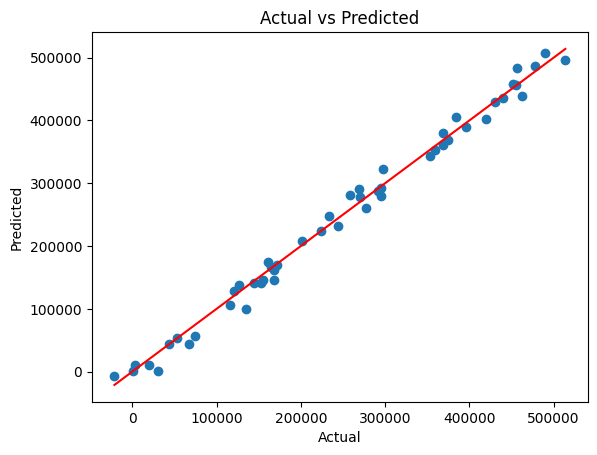

In [19]:
# 6. Simple Visualization
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted')
plt.show()